# Modelos de crecimiento celular de *Trichoderma atroviride*

Notebook para el análisis de crecimiento celular utilizado en la tesis.

Se comparan:

- Modelo Logístico.
- Modelo de Gompertz modificado.

Los parámetros se estiman directamente a partir de los datos mediante regresión no lineal por mínimos cuadrados (`scipy.optimize.curve_fit`). Las métricas \(R^2\) y RMSE se calculan automáticamente sobre las mismas observaciones para ambos modelos.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120
})


## 1. Datos experimentales


In [ ]:
# Tiempo (h), biomasa media (g/L) y desviación estándar experimental (g/L)
t = np.array([0, 6, 12, 18, 24, 30, 36, 42, 48, 54, 60, 66, 72, 78, 84, 90, 96, 102], dtype=float)

X = np.array([
    0.0059, 0.0059, 0.034, 0.034, 0.145, 0.145,
    0.601, 0.601, 1.377, 1.377, 3.203, 3.203,
    4.104, 4.280, 3.959, 4.219, 4.219, 4.219
], dtype=float)

X_sd = np.array([
    0.001, 0.001, 0.008, 0.008, 0.025, 0.025,
    0.089, 0.089, 0.198, 0.198, 0.312, 0.312,
    0.387, 0.370, 0.301, 0.280, 0.280, 0.280
], dtype=float)

datos = pd.DataFrame({
    "Tiempo (h)": t,
    "Biomasa (g/L)": X,
    "DE experimental (g/L)": X_sd
})
datos


,Tiempo (h),Biomasa (g/L),DE experimental (g/L)
0,0.0,0.0059,0.001
1,6.0,0.0059,0.001
2,12.0,0.0340,0.008
3,18.0,0.0340,0.008
4,24.0,0.1450,0.025
5,30.0,0.1450,0.025
6,36.0,0.6010,0.089
7,42.0,0.6010,0.089
8,48.0,1.3770,0.198
9,54.0,1.3770,0.198


## 2. Definición de los modelos

### Logístico

\[
X(t)=\frac{X_{\max}}{1+\exp[-\mu(t-t_{\mathrm{inf}})]}
\]

En esta parametrización, \(t_{\mathrm{inf}}\) corresponde al **tiempo del punto de inflexión** de la curva, no al tiempo de latencia.

### Gompertz modificado

\[
X(t)=X_{\max}\exp\left\{-\exp\left[\frac{\mu_{\max}e}{X_{\max}}(\lambda-t)+1\right]\right\}
\]

En esta formulación, \(\lambda\) representa el parámetro de tiempo de latencia y \(\mu_{\max}\) tiene unidades de concentración de biomasa por unidad de tiempo.


In [ ]:
def logistico(t, Xmax, mu, t_inf):
    return Xmax / (1.0 + np.exp(-mu * (t - t_inf)))

def gompertz_mod(t, Xmax, mu_max, lam):
    return Xmax * np.exp(
        -np.exp((mu_max * np.e / Xmax) * (lam - t) + 1.0)
    )


## 3. Ajuste por mínimos cuadrados no lineales


In [ ]:
# Valores iniciales razonables.
p0_log = [4.3, 0.12, 55.0]
p0_gom = [4.4, 0.14, 39.0]

# Restricciones: parámetros positivos y tiempos dentro del intervalo experimental.
bounds = ([0.0, 0.0, 0.0], [np.inf, np.inf, 102.0])

popt_log, pcov_log = curve_fit(
    logistico, t, X,
    p0=p0_log,
    bounds=bounds,
    maxfev=100000
)

popt_gom, pcov_gom = curve_fit(
    gompertz_mod, t, X,
    p0=p0_gom,
    bounds=bounds,
    maxfev=100000
)

# Error estándar aproximado a partir de la matriz de covarianza.
se_log = np.sqrt(np.diag(pcov_log))
se_gom = np.sqrt(np.diag(pcov_gom))

print("Logístico:", popt_log)
print("Gompertz :", popt_gom)


Logístico: [ 4.27593197  0.13238591 55.31293275]
Gompertz : [ 4.40937942  0.13635555 38.70437429]


> **Nota sobre la incertidumbre:** los errores estándar anteriores provienen de la matriz de covarianza del ajuste no lineal. Son una estimación local de la incertidumbre de los parámetros y no deben confundirse con la desviación estándar experimental de la biomasa.


## 4. Métricas de ajuste


In [ ]:
pred_log = logistico(t, *popt_log)
pred_gom = gompertz_mod(t, *popt_gom)

def metricas(y_obs, y_pred):
    r2 = r2_score(y_obs, y_pred)
    rmse = np.sqrt(mean_squared_error(y_obs, y_pred))
    return r2, rmse

r2_log, rmse_log = metricas(X, pred_log)
r2_gom, rmse_gom = metricas(X, pred_gom)

tabla_modelos = pd.DataFrame({
    "Modelo": ["Logístico", "Gompertz modificado"],
    "R²": [r2_log, r2_gom],
    "RMSE (g/L)": [rmse_log, rmse_gom]
})

tabla_modelos.round(4)


,Modelo,R²,RMSE (g/L)
0,Logístico,0.9853,0.2184
1,Gompertz modificado,0.9791,0.2605


## 5. Parámetros estimados


In [ ]:
tabla_parametros = pd.DataFrame({
    "Modelo": [
        "Logístico", "Logístico", "Logístico",
        "Gompertz", "Gompertz", "Gompertz"
    ],
    "Parámetro": [
        "Xmax", "mu", "t_inf",
        "Xmax", "mu_max", "lambda"
    ],
    "Valor": [
        *popt_log,
        *popt_gom
    ],
    "Error estándar aprox.": [
        *se_log,
        *se_gom
    ],
    "Unidad": [
        "g/L", "h^-1", "h",
        "g/L", "g L^-1 h^-1", "h"
    ]
})

tabla_parametros.round(5)


,Modelo,Parámetro,Valor,Error estándar aprox.,Unidad
0,Logístico,Xmax,4.27593,0.12365,g/L
1,Logístico,mu,0.13239,0.01670,h^-1
2,Logístico,t_inf,55.31293,1.13057,h
3,Gompertz,Xmax,4.40938,0.19181,g/L
4,Gompertz,mu_max,0.13636,0.01893,g L^-1 h^-1
5,Gompertz,lambda,38.70437,2.20850,h


## 6. Ajuste de los modelos y análisis de residuos


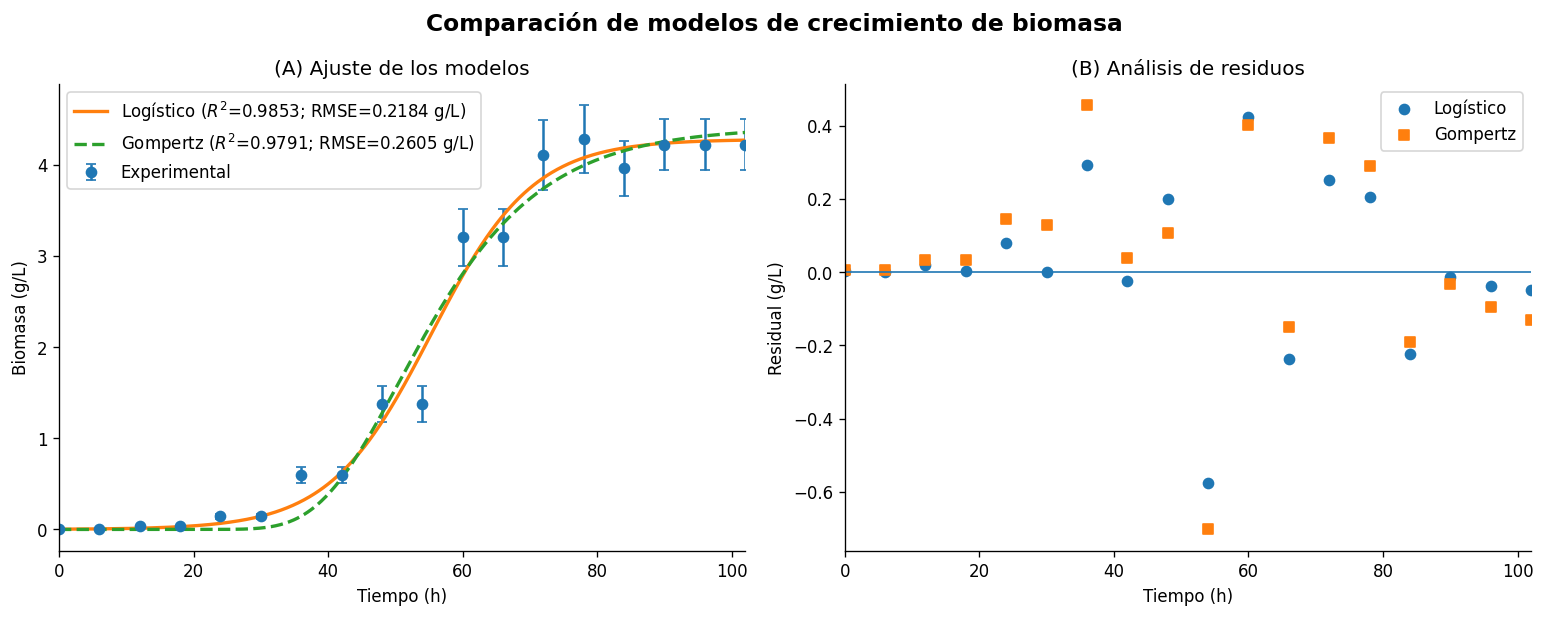

In [ ]:
# ============================================================
# Figura combinada: ajuste de modelos + análisis de residuos
# ============================================================

t_fine = np.linspace(0, 102, 600)

# Predicciones en los tiempos experimentales
pred_log = logistico(t, *popt_log)
pred_gom = gompertz_mod(t, *popt_gom)

# Residuos
res_log = X - pred_log
res_gom = X - pred_gom

# Crear figura con dos paneles
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13, 5.2)
)

# ------------------------------------------------------------
# (A) Ajuste de los modelos
# ------------------------------------------------------------

ax1.errorbar(
    t, X,
    yerr=X_sd,
    fmt="o",
    capsize=3,
    label="Experimental"
)

ax1.plot(
    t_fine,
    logistico(t_fine, *popt_log),
    linewidth=2.0,
    label=f"Logístico ($R^2$={r2_log:.4f}; RMSE={rmse_log:.4f} g/L)"
)

ax1.plot(
    t_fine,
    gompertz_mod(t_fine, *popt_gom),
    linewidth=2.0,
    linestyle="--",
    label=f"Gompertz ($R^2$={r2_gom:.4f}; RMSE={rmse_gom:.4f} g/L)"
)

ax1.set_xlabel("Tiempo (h)")
ax1.set_ylabel("Biomasa (g/L)")
ax1.set_title("(A) Ajuste de los modelos")
ax1.set_xlim(0, 102)
ax1.legend()


# ------------------------------------------------------------
# (B) Análisis de residuos
# ------------------------------------------------------------

ax2.axhline(0, linewidth=1)

ax2.scatter(
    t,
    res_log,
    label="Logístico"
)

ax2.scatter(
    t,
    res_gom,
    marker="s",
    label="Gompertz"
)

ax2.set_xlabel("Tiempo (h)")
ax2.set_ylabel("Residual (g/L)")
ax2.set_title("(B) Análisis de residuos")
ax2.set_xlim(0, 102)
ax2.legend()


# ------------------------------------------------------------
# Título general
# ------------------------------------------------------------

fig.suptitle(
    "Comparación de modelos de crecimiento de biomasa",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

⏰:## 7. Resumen


In [ ]:
print("RESULTADOS DEL AJUSTE")
print("-" * 60)

print(
    f"Logístico: Xmax={popt_log[0]:.4f} g/L, "
    f"mu={popt_log[1]:.5f} h^-1, "
    f"t_inf={popt_log[2]:.2f} h, "
    f"R²={r2_log:.4f}, RMSE={rmse_log:.4f} g/L."
)

print(
    f"Gompertz: Xmax={popt_gom[0]:.4f} g/L, "
    f"mu_max={popt_gom[1]:.5f} g L^-1 h^-1, "
    f"lambda={popt_gom[2]:.2f} h, "
    f"R²={r2_gom:.4f}, RMSE={rmse_gom:.4f} g/L."
)

if (r2_log > r2_gom) and (rmse_log < rmse_gom):
    print("\nSegún R² y RMSE, el modelo Logístico presenta el mejor ajuste descriptivo.")
elif (r2_gom > r2_log) and (rmse_gom < rmse_log):
    print("\nSegún R² y RMSE, el modelo Gompertz presenta el mejor ajuste descriptivo.")
else:
    print("\nLas métricas no favorecen simultáneamente al mismo modelo; se requiere interpretar ambos criterios.")


RESULTADOS DEL AJUSTE
------------------------------------------------------------
Logístico: Xmax=4.2759 g/L, mu=0.13239 h^-1, t_inf=55.31 h, R²=0.9853, RMSE=0.2184 g/L.
Gompertz: Xmax=4.4094 g/L, mu_max=0.13636 g L^-1 h^-1, lambda=38.70 h, R²=0.9791, RMSE=0.2605 g/L.

Según R² y RMSE, el modelo Logístico presenta el mejor ajuste descriptivo.
